# 3.1 Data Wrangling with MongoDB

**Purpose.** Get the Nairobi air-quality sensor readings out of MongoDB and into a clean, time-indexed pandas DataFrame that later notebooks (modelling) can reuse.

**Data.** `nairobi.parquet`, provided as part of the course materials, loaded into a local MongoDB 7 container (database `air-quality`, collection `nairobi`) with `src/load_mongo_data.py`. The raw file is not committed to the repo.

**Method.** Connect with `pymongo`, explore the collection (counts, one document, distinct sensors and measurement types, an aggregation pipeline), query PM2.5 readings (`value_type == "P2"`), convert to a DataFrame, and package the steps in a reusable `wrangle_data()` function in `src/`.

In [1]:
import os
import sys
from pprint import PrettyPrinter

import pandas as pd
from pymongo import MongoClient

sys.path.append("../src")

pp = PrettyPrinter(indent=2)

In [2]:
host = os.environ.get("MONGO_HOST", "localhost")
port = 27017
client = MongoClient(f"mongodb://{host}:{port}", serverSelectionTimeoutMS=3000)

database_list = client.list_database_names()
pp.pprint(database_list)

['admin', 'air-quality', 'config', 'local']


In [4]:
# Select the database and list its collections
db = client["air-quality"]
collection_list = db.list_collection_names()
print(collection_list)

# Select the collection
nairobi = db["nairobi"]

['nairobi']


## Explore the collection

Before pulling any data into pandas, check how many documents there are, what one looks like, and which sensors and measurement types exist.

In [5]:
# Count all documents
total_documents = nairobi.count_documents({})
print(f"Total documents: {total_documents:,}")

# Look at one document
sample_document = nairobi.find_one()
pp.pprint(sample_document)

Total documents: 10,000
{ '_id': ObjectId('6ae861200fe49655098511dc'),
  'location': {'lat': -1.2696061360394681, 'lon': 36.79165988896354},
  'sensor_id': 'nairobi_009',
  'timestamp': datetime.datetime(2024, 1, 1, 0, 0),
  'value': 45.42,
  'value_type': 'P2'}


In [6]:
# Distinct sensors and measurement types
unique_sensors = nairobi.distinct("sensor_id")
print(f"Number of unique sensors: {len(unique_sensors)}")
print(f"First 5 sensors: {unique_sensors[:5]}")

measurement_types = nairobi.distinct("value_type")
print(f"Measurement types: {measurement_types}")

Number of unique sensors: 10
First 5 sensors: ['nairobi_001', 'nairobi_002', 'nairobi_003', 'nairobi_004', 'nairobi_005']
Measurement types: ['P2']


### What the collection contains

- **10,000 documents** from **10 sensors** (`nairobi_001` onwards), all with `value_type == "P2"` (PM2.5). No other measurement types are present, so the PM2.5 filter used later does not remove any rows here; it is kept so the function stays correct if other types are added.
- Each document holds `timestamp`, `sensor_id`, `value_type`, `value` and an embedded `location` document (`lat`, `lon`). The sample reading, from `nairobi_009` at 2024-01-01 00:00, is 45.42.
- `timestamp` is stored as a native date with no timezone, so no string parsing is needed. The next step has to decide which timezone it represents; the lesson assumes UTC.
- The `_id` field is MongoDB's internal identifier and is dropped in the DataFrame.

In [7]:
pipeline = [
    {"$group": {
        "_id": "$sensor_id",
        "readings": {"$sum": 1},
        "first": {"$min": "$timestamp"},
        "last": {"$max": "$timestamp"},
    }},
    {"$sort": {"_id": 1}},
]

sensor_summary = (
    pd.DataFrame(list(nairobi.aggregate(pipeline)))
    .rename(columns={"_id": "sensor_id"})
)
print(sensor_summary)

     sensor_id  readings               first                last
0  nairobi_001       953 2024-01-01 09:00:00 2025-02-20 13:00:00
1  nairobi_002      1009 2024-01-01 11:00:00 2025-02-20 14:00:00
2  nairobi_003       972 2024-01-01 20:00:00 2025-02-20 08:00:00
3  nairobi_004      1047 2024-01-01 06:00:00 2025-02-20 03:00:00
4  nairobi_005       971 2024-01-01 02:00:00 2025-02-19 21:00:00
5  nairobi_006       994 2024-01-01 01:00:00 2025-02-20 15:00:00
6  nairobi_007      1032 2024-01-01 04:00:00 2025-02-20 11:00:00
7  nairobi_008      1051 2024-01-01 10:00:00 2025-02-20 02:00:00
8  nairobi_009       938 2024-01-01 00:00:00 2025-02-19 05:00:00
9  nairobi_010      1033 2024-01-01 07:00:00 2025-02-20 09:00:00


In [8]:
assert unique_sensors, "No sensors found in the collection"
first_sensor = sorted(unique_sensors)[0]

pipeline = [
    {"$match": {"sensor_id": first_sensor}},
    {"$group": {"_id": "$value_type", "count": {"$sum": 1}}},
    {"$sort": {"count": -1}},
]

sensor_type_counts = list(nairobi.aggregate(pipeline))
print(first_sensor)
pp.pprint(sensor_type_counts)

nairobi_001
[{'_id': 'P2', 'count': 953}]


### Coverage per sensor

- All 10 sensors report over the same period (2024-01-01 to 2025-02-20), with between 938 and 1,051 readings each. The counts sum to the 10,000 documents in the collection.
- Each sensor has roughly 1,000 readings spread over about 10,000 hours, so a single sensor's series is sparse and irregular (a reading roughly every ten hours on average), not hourly.
- The first sensor, `nairobi_001`, has 953 readings, all of type `P2`.

In [9]:
n_distinct = len(nairobi.distinct("timestamp"))
print(f"Distinct timestamps: {n_distinct:,} of {total_documents:,} documents")

Distinct timestamps: 10,000 of 10,000 documents


## Import PM2.5 readings into pandas

`find(filter, projection)` returns a lazy cursor. The projection keeps only `timestamp` and `value` and drops `_id`. First a five-document peek, then the full series for one sensor as a DataFrame.

In [10]:
pm25_sample = list(
    nairobi.find(
        {"sensor_id": first_sensor, "value_type": "P2"},
        projection={"timestamp": True, "value": True, "_id": False},
    ).limit(5)
)
pp.pprint(pm25_sample)

[ {'timestamp': datetime.datetime(2024, 1, 1, 9, 0), 'value': 27.75},
  {'timestamp': datetime.datetime(2024, 1, 1, 16, 0), 'value': 33.55},
  {'timestamp': datetime.datetime(2024, 1, 1, 23, 0), 'value': 34.51},
  {'timestamp': datetime.datetime(2024, 1, 2, 9, 0), 'value': 32.2},
  {'timestamp': datetime.datetime(2024, 1, 2, 16, 0), 'value': 39.99}]


In [11]:
df_raw = (
    pd.DataFrame(
        list(
            nairobi.find(
                {"sensor_id": first_sensor, "value_type": "P2"},
                projection={"timestamp": True, "value": True, "_id": False},
            )
        )
    )
    .assign(timestamp=lambda x: pd.to_datetime(x["timestamp"]))
    .set_index("timestamp")
    .sort_index()
)

print(df_raw.head())
print(f"\nShape: {df_raw.shape}")
print(f"Index dtype: {df_raw.index.dtype}")

                     value
timestamp                 
2024-01-01 09:00:00  27.75
2024-01-01 16:00:00  33.55
2024-01-01 23:00:00  34.51
2024-01-02 09:00:00  32.20
2024-01-02 16:00:00  39.99

Shape: (953, 1)
Index dtype: datetime64[us]


In [12]:
print("Missing values:")
print(df_raw.isnull().sum())

print("\nBasic statistics:")
print(df_raw.describe())

Missing values:
value    0
dtype: int64

Basic statistics:
            value
count  953.000000
mean    39.755792
std      9.816934
min      8.030000
25%     33.100000
50%     39.890000
75%     46.360000
max     67.410000


### Time index and one sensor's PM2.5

- All **10,000 timestamps are distinct** across the 10,000 documents, so no two readings in the collection share a time, even across sensors. Combining sensors therefore does not create duplicate index entries.
- `nairobi_001` has **953 readings and no missing values**. PM2.5 averages 39.8 (median 39.9, standard deviation 9.8) and ranges from 8.0 to 67.4. Mean and median are close, so the distribution looks roughly symmetric.
- The DataFrame index is a timezone-naive `datetime64[us]`. It becomes timezone-aware only in `wrangle_data()`, which assumes the stored times are UTC (the course's assumption; the data itself does not say).
- The first readings for this sensor fall at 09:00, 16:00 and 23:00 on the first day. Whether the sensor reports on a fixed daily schedule is not established from five rows and is checked in the next lesson.

## A reusable wrangling function

The steps above are packaged as `wrangle_data()` in `src/mongo_wrangle.py`, so every later notebook starts with one import. It filters to PM2.5, optionally to one sensor, converts the stored UTC times to Africa/Nairobi, sorts, drops missing values and renames `value` to `pm25`.

In [13]:
from mongo_wrangle import wrangle_data

df_clean = wrangle_data()
print(df_clean.head())
print(f"\nShape: {df_clean.shape}")
print(f"Index dtype: {df_clean.index.dtype}")
print(f"Index unique: {df_clean.index.is_unique}")
print(f"Index sorted: {df_clean.index.is_monotonic_increasing}")
print(f"Missing values: {int(df_clean['pm25'].isnull().sum())}")

                            pm25
timestamp                       
2024-01-01 03:00:00+03:00  45.42
2024-01-01 04:00:00+03:00  28.71
2024-01-01 05:00:00+03:00  30.34
2024-01-01 06:00:00+03:00  28.35
2024-01-01 07:00:00+03:00  52.78

Shape: (10000, 1)
Index dtype: datetime64[us, Africa/Nairobi]
Index unique: True
Index sorted: True
Missing values: 0


In [14]:
# One sensor, and the gaps between consecutive readings of the combined series
df_one = wrangle_data(sensor_id="nairobi_001")
print(f"nairobi_001 shape: {df_one.shape}")

gaps = df_clean.index.to_series().diff().value_counts().head()
print("\nMost common gaps between consecutive readings (all sensors):")
print(gaps)

nairobi_001 shape: (953, 1)

Most common gaps between consecutive readings (all sensors):
timestamp
0 days 01:00:00    9999
Name: count, dtype: int64


### Result of `wrangle_data()`

- The combined series has **10,000 hourly readings** with a unique, sorted, timezone-aware index (`datetime64[us, Africa/Nairobi]`) and no missing values. The first reading, 45.42 from `nairobi_009`, appears as 03:00+03:00, which is the stored 00:00 shifted from UTC to Nairobi time.
- Every one of the 9,999 gaps between consecutive readings is exactly one hour, so the series is perfectly regular: one reading per hour, with no holes to fill.
- Filtering with `sensor_id="nairobi_001"` returns 953 rows, matching the per-sensor count from the aggregation.

**Limitations.**

- Each hourly value comes from *one* of the 10 sensors, at a different location, so the combined series is a patchwork of sensors rather than a single instrument's record. Differences between sensors and between locations show up as noise in the series; later models should be read with that in mind.
- Assuming the stored timestamps are UTC is the course's convention. The data does not state its timezone, so the conversion to Africa/Nairobi is an assumption.

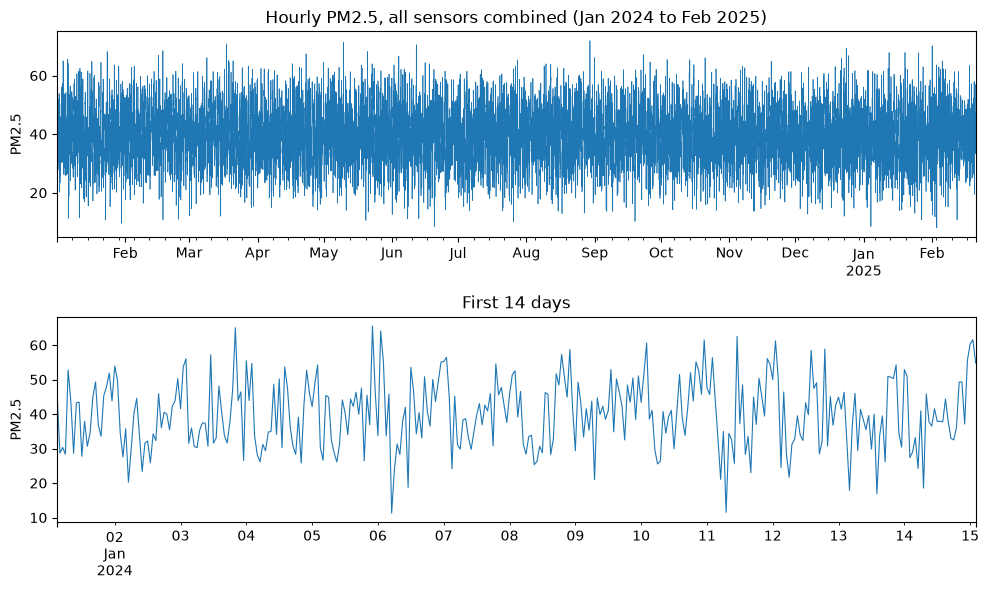

In [15]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(10, 6))

df_clean["pm25"].plot(ax=axes[0], lw=0.5)
axes[0].set_title("Hourly PM2.5, all sensors combined (Jan 2024 to Feb 2025)")

df_clean["pm25"].iloc[: 24 * 14].plot(ax=axes[1], lw=0.8)
axes[1].set_title("First 14 days")

for ax in axes:
    ax.set_ylabel("PM2.5")
    ax.set_xlabel("")

fig.tight_layout()
fig.savefig("../reports/figures/pm25_hourly_series.png", dpi=150)
plt.show()